In [2]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy.optimize import leastsq
from scipy.optimize import curve_fit

In [ ]:
#funties om te gebruiken
def importeer(datanaam):
    x_as = []
    y_as = []

    # open file in read mode
    with open(datanaam, 'r', newline='') as file:

        # read and discard first line of file
        next(file)

        for line in file:
            # split column

            line_splitted = line.split(',')
            x = (float(line_splitted[3]))
            y = float(line_splitted[4])
            if x < 0.015:
                x_as.append(x)
                y_as.append(y)

    return x_as, y_as

def lineaire_functie(x,a,b):
    return a*x + b
def plot(x_as, y_as, x_label, y_label, title):
    plt.plot(x_as, y_as, )
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.show()

def lorentz(x, x0, gamma, A):
    return A * (0.5*gamma)**2 / ((x - x0)**2 + (0.5*gamma)**2)

def multi_lorentz(x, *params):
    # Laatste parameter is de achtergrond
    B = params[-1]
    y_model = np.zeros_like(x) + B

    # Door de overige parameters in stapjes van 3 lopen
    # (x0, gamma, A) per piek
    for i in range(0, len(params) - 1, 3):
        x0 = params[i]
        gamma = params[i + 1]
        A = params[i + 2]
        y_model += lorentz(x, x0, gamma, A)

    return y_model

def subtract(background_link, real_link):
    x_bg, y_bg = importeer(background_link)
    x_real, y_real = importeer(real_link)

    y_interpolated = np.interp(x_real, x_bg, y_bg)
    y_subtracted = y_real - y_interpolated

    return x_real, y_subtracted

#now we need to find a lorenzian function somehow...
x = np.array(x_subtracted)
y_subtracted = np.array(y_subtracted)

x0_list = [-0.010, -0.007, 0, 0.006 ]  
gamma_guess = 0.001  
B_guess = 0.001     

p0 = []  # startwaarden
A_list = [-0.07, -0.03, -0.005, -0.005 ]  # schat per piek visueel

for x0, A_guess in zip(x0_list, A_list):
    p0.extend([x0, gamma_guess, A_guess])

p0.append(B_guess)

popt, pcov = curve_fit(multi_lorentz, x, y_subtracted, p0=p0)
y_fit = multi_lorentz(x, *popt)

plt.plot(x, y_subtracted, label='Gegevens na Lineaire Correctie', color='green')
plt.plot(x, y_fit, label='Lorentz Fit', color='orange')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.title('Data met Lorentz Fit')
plt.legend()
plt.show()

N = len(x0_list)  # aantal pieken

import numpy as np

perr = np.sqrt(np.diag(pcov))  # standaardafwijking per parameter

for i in range(N):
    print(f"Piek {i+1}: x0 = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
    print(f"         gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
    print(f"         A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")

print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")

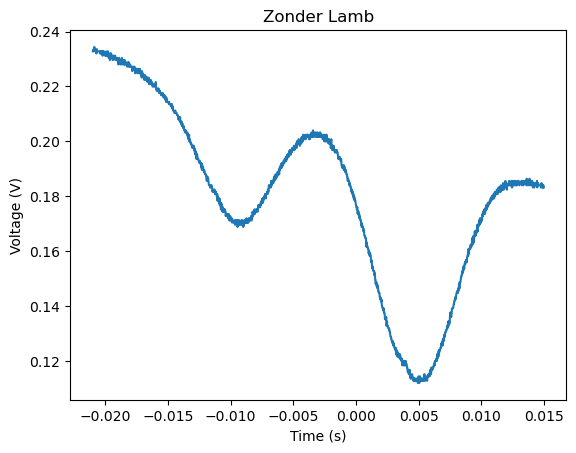

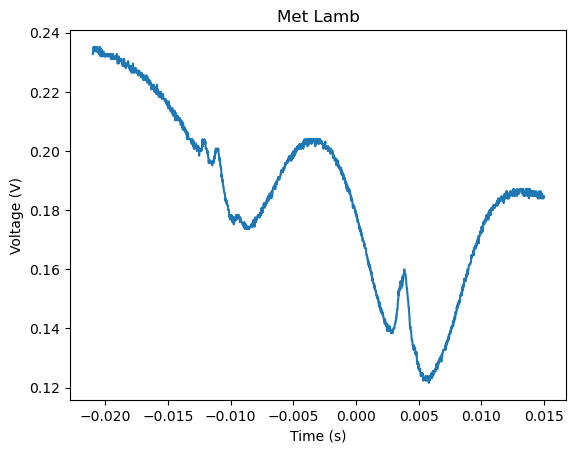

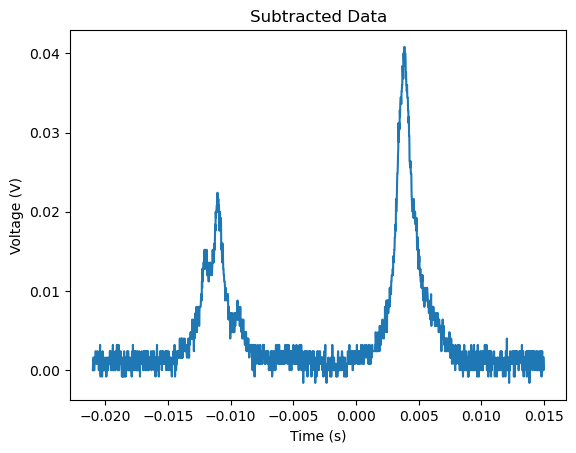

In [20]:
#Importeren van de Data: 
Lamb_dip = '/Users/timwiemer/Desktop/Natuur-: Sterrenkunde/Jaar 1/Project/Rubium_Spectroscopy/programmas.venv/met_LAMB.CSV'
without_dip = '/Users/timwiemer/Desktop/Natuur-: Sterrenkunde/Jaar 1/Project/Rubium_Spectroscopy/programmas.venv/zonder_LAMB.CSV'

x_1, y_1 = importeer(without_dip)
plot(x_1, y_1, 'Time (s)', 'Voltage (V)', 'Zonder Lamb')

x_2, y_2 = importeer(Lamb_dip)
plot(x_2, y_2, 'Time (s)', 'Voltage (V)', 'Met Lamb')

x_subtracted, y_subtracted = subtract(without_dip, Lamb_dip)
plot(x_subtracted, y_subtracted, 'Time (s)', 'Voltage (V)', 'Subtracted Data')

─────────────────────────────────────────────
Piek 1:
  x0    = -0.01206 ± 0.00002
  gamma = 0.00052 ± 0.00003
  A     = 0.00972 ± 0.00032
Piek 2:
  x0    = -0.01096 ± 0.00001
  gamma = 0.00046 ± 0.00002
  A     = 0.01783 ± 0.00033
Piek 3:
  x0    = -0.00935 ± 0.00003
  gamma = 0.00049 ± 0.00006
  A     = 0.00427 ± 0.00028
Piek 4:
  x0    = 0.00391 ± 0.00000
  gamma = 0.00074 ± 0.00001
  A     = 0.03767 ± 0.00023
Achtergrond B = 0.00078 ± 0.00004
─────────────────────────────────────────────


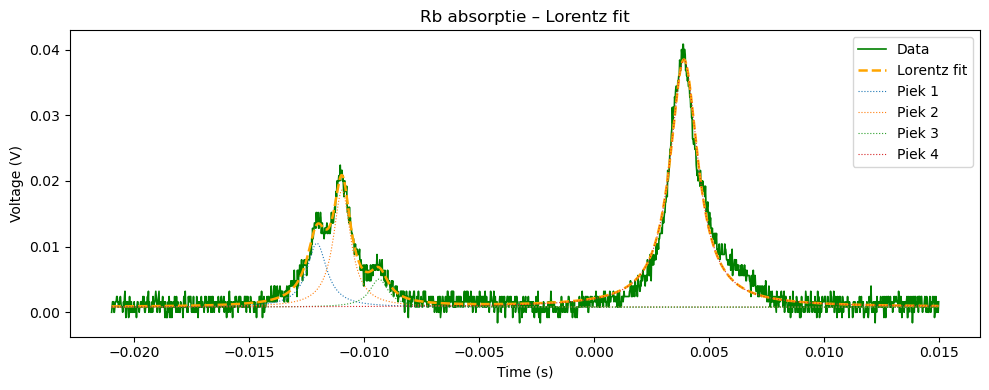

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


# ── Lorentz bouwstenen ────────────────────────────────────────────────────────

def lorentz(x, x0, gamma, A):
    """Enkele Lorentz-piek (absorptie → negatieve A)."""
    return A * ( gamma)**2 / ((x - x0)**2 + (gamma)**2)

def multi_lorentz(x, *params):
    """
    Som van N Lorentz-pieken + constante achtergrond.
    params = [x0_1, gamma_1, A_1,  x0_2, gamma_2, A_2,  ...,  B]
    """
    B = params[-1]
    y = np.zeros_like(x, dtype=float) + B
    for i in range(0, len(params) - 1, 3):
        y += lorentz(x, params[i], params[i+1], params[i+2])
    return y


# ── Hoofd-fitfunctie ──────────────────────────────────────────────────────────

def lorentz_fit(x, y, x0_list, A_list,
                gamma_guess=0.001, B_guess=0.0,
                plot=True, title='Lorentz Fit'):
    """
    Fit een willekeurig aantal Lorentz-pieken op (x, y).

    Parameters
    ----------
    x, y        : array-like  – meetdata
    x0_list     : list        – beginschattingen voor piekposities
    A_list      : list        – beginschattingen voor amplitudes (negatief = absorptie)
    gamma_guess : float       – beginschatting breedte (zelfde voor alle pieken)
    B_guess     : float       – beginschatting achtergrond
    plot        : bool        – toon figuur
    title       : str         – figuurtitel

    Returns
    -------
    popt  : array  – geoptimaliseerde parameters [x0, gamma, A, ..., B]
    perr  : array  – 1-sigma onzekerheden
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x0_list) != len(A_list):
        raise ValueError("x0_list en A_list moeten even lang zijn.")

    # Startwaarden opbouwen
    p0 = []
    for x0, A in zip(x0_list, A_list):
        p0.extend([x0, gamma_guess, A])
    p0.append(B_guess)

    # Fit
    popt, pcov = curve_fit(multi_lorentz, x, y, p0=p0, maxfev=10000)
    perr = np.sqrt(np.diag(pcov))
    y_fit = multi_lorentz(x, *popt)

    # Resultaten printen
    N = len(x0_list)
    print(f"{'─'*45}")
    for i in range(N):
        print(f"Piek {i+1}:")
        print(f"  x0    = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
        print(f"  gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
        print(f"  A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")
    print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")
    print(f"{'─'*45}")

    # Plot
    if plot:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(x, y,     color='green',  label='Data', lw=1.2)
        ax.plot(x, y_fit, color='orange', label='Lorentz fit', lw=1.8, ls='--')

        # Individuele pieken (stippellijnen)
        for i in range(N):
            x0_i, g_i, A_i = popt[i*3], popt[i*3+1], popt[i*3+2]
            B_i = popt[-1]
            y_i = lorentz(x, x0_i, g_i, A_i) + B_i
            ax.plot(x, y_i, lw=0.8, ls=':', label=f'Piek {i+1}')

        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Voltage (V)')
        ax.set_title(title)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return popt, perr


# ── Gebruik ───────────────────────────────────────────────────────────────────

# Vervang x_subtracted en y_subtracted door jouw arrays
# x_subtracted, y_subtracted = subtract(background_link, real_link)

x0_list  = [-0.013, -0.011, -0.010,  0.004]
A_list   = [0.015, 0.023, 0.01, 0.04]

popt, perr = lorentz_fit(
    x_subtracted, y_subtracted,
    x0_list     = x0_list,
    A_list      = A_list,
    gamma_guess = 0.001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit'
)


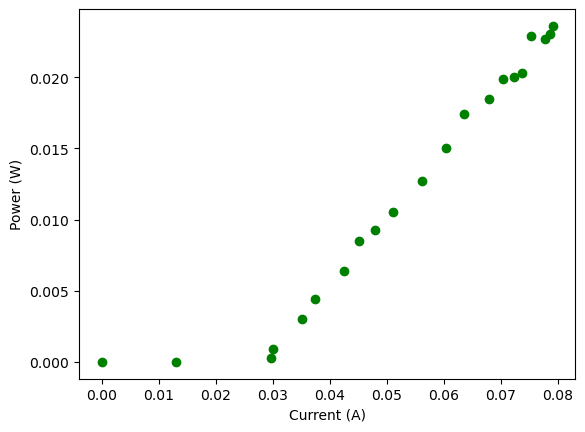

In [17]:
Current = [0.02E-3, 78.63E-3, 51.09E-3, 42.51E-3, 29.72E-3, 56.23E-3, 13.04E-3, 30E-3, 35.09E-3, 37.5E-3, 45.12E-3, 47.87E-3, 63.47E-3, 67.98E-3,
           70.32E-3, 60.46E-3, 75.31E-3, 72.26E-3, 73.76E-3, 77.75E-3, 79.07E-3]

Power = [0, 23E-3, 10.5E-3, 6.4E-3, 0.3E-3, 12.7E-3, 0, 0.9E-3, 3E-3, 4.4E-3, 8.5E-3, 9.3E-3, 17.4E-3, 18.5E-3, 19.9E-3, 15E-3, 22.9E-3 , 20E-3,
         20.3E-3, 22.7E-3, 23.6E-3]

plt.scatter(Current, Power, label='Power vs Current', color='green')
plt.xlabel('Current (A)')
plt.ylabel('Power (W)')
plt.show()